Poisson Equation

$\\\nabla^2u(x,y)=\frac{\partial^2u(x,y)}{\partial x^2}+\frac{\partial^2u(x,y)}{\partial y^2}=f(x,y)\\$
$f(x,y)=-2\pi sin(\pi x)\sin(\pi y)$

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.rand(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def basis_matrix(self, x, degree=None, knots=None):
        """Evaluate all B-spline basis functions without autograd."""
        degree = self.degree if degree is None else degree
        knots = self.knot_vector if knots is None else knots
        knots = knots.to(device=x.device, dtype=x.dtype)
        B = ((x[:, None] >= knots[:-1]) &
             (x[:, None] < knots[1:])).to(x.dtype)
        for p in range(1, degree + 1):
            n = len(knots) - p - 1
            next_B = torch.zeros((x.numel(), n), device=x.device, dtype=x.dtype)
            for i in range(n):
                denom1 = knots[i + p] - knots[i]
                denom2 = knots[i + p + 1] - knots[i + 1]
                if denom1 > 0:
                    next_B[:, i] += (x - knots[i]) / denom1 * B[:, i]
                if denom2 > 0:
                    next_B[:, i] += (knots[i + p + 1] - x) / denom2 * B[:, i + 1]
            B = next_B
        at_right_endpoint = x == knots[-1]
        if torch.any(at_right_endpoint):
            B[at_right_endpoint] = 0
            B[at_right_endpoint, -1] = 1
        return B

    def basis_and_second_derivative(self, x, knots=None):
        """Return B_{i,p}(x) and its analytic second derivative."""
        knots = self.knot_vector if knots is None else knots
        knots = knots.to(device=x.device, dtype=x.dtype)
        p = self.degree
        if p < 2:
            raise ValueError('Second derivatives require degree >= 2')
        B = self.basis_matrix(x, degree=p, knots=knots)
        B_low = self.basis_matrix(x, degree=p - 2, knots=knots)
        D_low = torch.zeros((x.numel(), self.n_basis + 1),
                            device=x.device, dtype=x.dtype)
        q = p - 1
        for i in range(self.n_basis + 1):
            denom1 = knots[i + q] - knots[i]
            denom2 = knots[i + q + 1] - knots[i + 1]
            if denom1 > 0:
                D_low[:, i] += q / denom1 * B_low[:, i]
            if denom2 > 0:
                D_low[:, i] -= q / denom2 * B_low[:, i + 1]
        D2 = torch.zeros_like(B)
        for i in range(self.n_basis):
            denom1 = knots[i + p] - knots[i]
            denom2 = knots[i + p + 1] - knots[i + 1]
            if denom1 > 0:
                D2[:, i] += p / denom1 * D_low[:, i]
            if denom2 > 0:
                D2[:, i] -= p / denom2 * D_low[:, i + 1]
        return B, D2

    def forward(self, x):
        B_x = self.basis_matrix(x[:, 0], knots=self.knot_x)[:, 1:-1]
        B_y = self.basis_matrix(x[:, 1], knots=self.knot_y)[:, 1:-1]
        return torch.einsum('ni,ij,nj->n', B_x, self.coeffs[1:-1, 1:-1], B_y)

In [3]:
torch.manual_seed(42)
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')

# model = bsplines(10,3)
model = bsplines(20,3)
# model.coeffs.to(device)


In [4]:
torch.manual_seed(42)
colloc_points = 5000
# x = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
# y = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
###########Changes#########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)
##########Changes###########
# X does not require gradients: coordinate derivatives are analytic.
# X.to(device)

In [5]:
###########Changes#################
# epochs = 6000
epochs = 20000

###########Changes#################
learning_rate=1e-3
# learning_rate=1e-4
###########Changes#################

# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

loss_vec = []

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.8, patience=50, verbose=True, min_lr=1e-5
)

# Early stopping monitors the fixed collocation residual. Its patience is
# intentionally longer than the scheduler patience, allowing several LR drops.
early_stopping_patience = 500
min_delta = 1e-8
best_loss = float('inf')
best_coeffs = model.coeffs.detach().clone()
patience_counter = 0
###########Changes#################

# Precompute the fixed B-spline Laplacian collocation operator once.
with torch.no_grad():
    Bx, Bxx = model.basis_and_second_derivative(X[:, 0], model.knot_x)
    By, Byy = model.basis_and_second_derivative(X[:, 1], model.knot_y)
    Bx, Bxx = Bx[:, 1:-1], Bxx[:, 1:-1]
    By, Byy = By[:, 1:-1], Byy[:, 1:-1]
    laplacian_matrix = (
        Bxx[:, :, None] * By[:, None, :]
        + Bx[:, :, None] * Byy[:, None, :]
    ).reshape(X.shape[0], -1)
    source = f(X[:, 0], X[:, 1])

for epoch in range(epochs):
    optimizer.zero_grad()
    interior_coeffs = model.coeffs[1:-1, 1:-1].reshape(-1)
    res = laplacian_matrix @ interior_coeffs - source
    
    loss = torch.mean(res**2)
    
    loss.backward()
    ###########Changes#################
    optimizer.step()

    loss_value = loss.item()
    scheduler.step(loss_value)

    # A decrease must exceed min_delta to count as an improvement.
    if loss_value < best_loss - min_delta:
        best_loss = loss_value
        best_coeffs = model.coeffs.detach().clone()
        patience_counter = 0
    else:
        patience_counter += 1
    

    loss_vec.append(loss_value)
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss_value}, LR: {current_lr:.2e}')

    if patience_counter >= early_stopping_patience:
        print(f'Early stopping at epoch {epoch + 1}; best loss: {best_loss:.6e}')
        break

# Continue with the best coefficients rather than the final stagnant iterate.
with torch.no_grad():
    model.coeffs.copy_(best_coeffs)

c:\Users\Polydoras\Documents\Sisc\PhD\papers\PI_bsplines\.venv\lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch [5/20000], Loss: 86125.9609375, LR: 1.00e-03
Epoch [10/20000], Loss: 83961.03125, LR: 1.00e-03
Epoch [15/20000], Loss: 81845.328125, LR: 1.00e-03
Epoch [20/20000], Loss: 79780.6015625, LR: 1.00e-03
Epoch [25/20000], Loss: 77767.9765625, LR: 1.00e-03
Epoch [30/20000], Loss: 75807.9921875, LR: 1.00e-03
Epoch [35/20000], Loss: 73900.65625, LR: 1.00e-03
Epoch [40/20000], Loss: 72045.5078125, LR: 1.00e-03
Epoch [45/20000], Loss: 70241.6796875, LR: 1.00e-03
Epoch [50/20000], Loss: 68488.0859375, LR: 1.00e-03
Epoch [55/20000], Loss: 66783.4609375, LR: 1.00e-03
Epoch [60/20000], Loss: 65126.4765625, LR: 1.00e-03
Epoch [65/20000], Loss: 63515.71875, LR: 1.00e-03
Epoch [70/20000], Loss: 61949.8125, LR: 1.00e-03
Epoch [75/20000], Loss: 60427.3671875, LR: 1.00e-03
Epoch [80/20000], Loss: 58947.03515625, LR: 1.00e-03
Epoch [85/20000], Loss: 57507.5, LR: 1.00e-03
Epoch [90/20000], Loss: 56107.51171875, LR: 1.00e-03
Epoch [95/20000], Loss: 54745.84375, LR: 1.00e-03
Epoch [100/20000], Loss: 5342

In [37]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save(loss_vec_npy, './results/poisson/bsplines_loss.npy')

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs }
torch.save(params, './results/poisson/model_bsplines.pth')

In [4]:
# Load model trainable parameters
model_s = bsplines(20,3)
loaded_params = torch.load('./results/poisson/model_bsplines.pth')
model_s.coeffs = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_29316\1858842893.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/poisson/model_bspl

In [5]:
#Load bsplines loss
loss_bsplines_s = np.load('./results/poisson/bsplines_loss.npy')

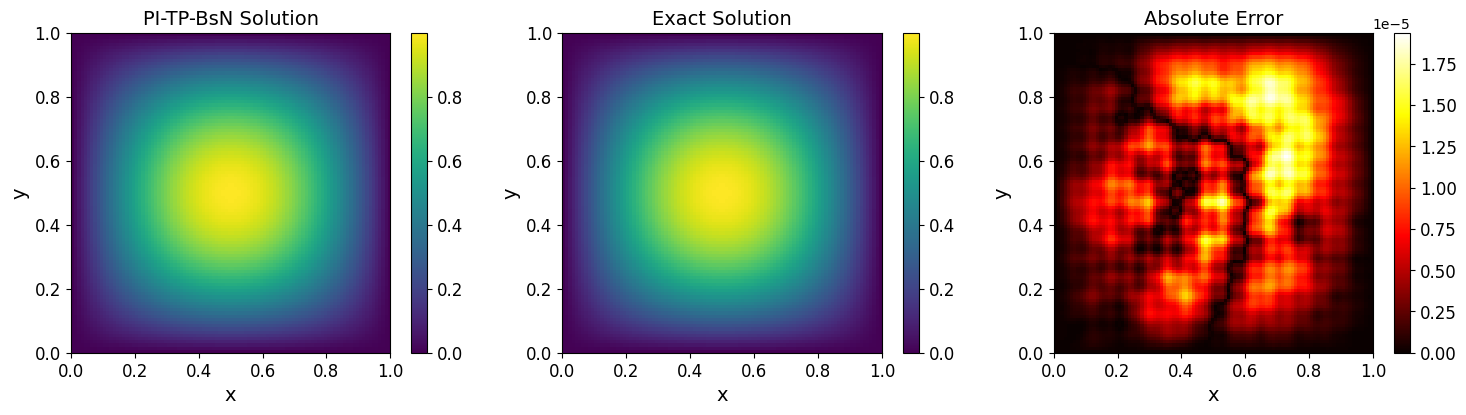

In [6]:
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("PI-TP-BsN Solution",fontsize=14)
cbar = fig.colorbar(im0, ax=axs[0])
cbar.ax.tick_params(labelsize=12) 

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution",fontsize=14)
cbar = fig.colorbar(im1, ax=axs[1])
cbar.ax.tick_params(labelsize=12) 

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error",fontsize=14)
cbar = fig.colorbar(im2, ax=axs[2])
cbar.ax.tick_params(labelsize=12) 



for ax in axs:
    ax.set_xlabel("x",fontsize=14)
    ax.set_ylabel("y",fontsize=14)
    ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.show()

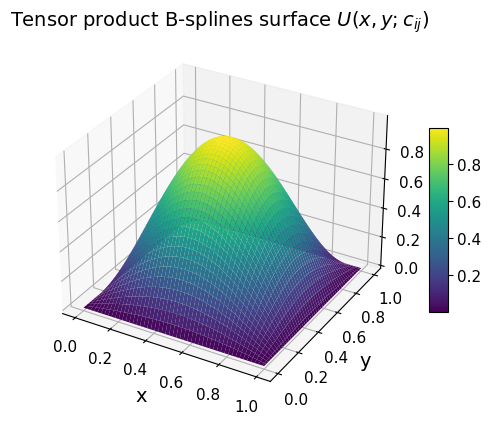

In [8]:
# Figure 4

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
# fig, axs = plt.subplots(1, 3, figsize=(15, 4))


# Plot surface
surf = ax.plot_surface(Xg, Yg, u_pred, cmap='viridis')  # Note the .T for correct orientation

# Add labels and colorbar
ax.set_title('Tensor product B-splines surface $U(x,y;c_{ij})$',fontsize=14)
ax.set_xlabel('x',fontsize=14)
ax.set_ylabel('y',fontsize=14)
ax.set_zlabel('u',fontsize=14)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10).ax.tick_params(labelsize=11) 
ax.tick_params(axis='both', labelsize=11)
# plt.savefig("surface_DC_poisson.pdf")
plt.show()

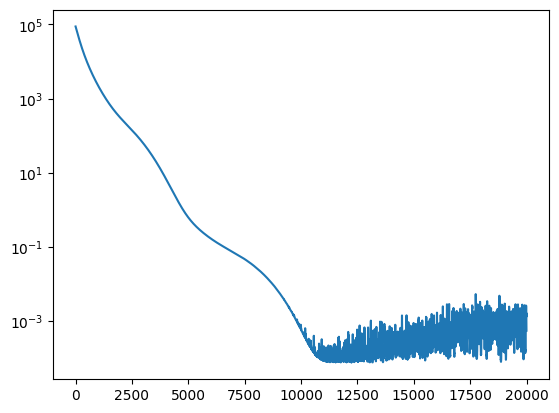

In [9]:
plt.plot(loss_bsplines_s)
plt.yscale('log')

PINN for 2D poisson equation

In [23]:

# First we are implementing hyperparameter tuning based on optuna with Tree-structured Parzen Estimator (TPE) algorithm.

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import optuna
import random
torch.manual_seed(42)
# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # Force deterministic behavior in CuDNN (can slow training)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
# PINN model
# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"layer{i}", nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh{i}", nn.Tanh())

    def forward(self, x):
        return self.net(x)

# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]
    laplace_u = u_xx + u_yy
    source = f(X[:, 0], X[:, 1])
    return torch.mean((laplace_u - source)**2)

# Boundary loss
def boundary_loss(model, Xb):
    return torch.mean(model(Xb)**2)

# Generate collocation and boundary points
def generate_points(n_interior, n_boundary):
    # Interior points
    xy_in = torch.rand(n_interior, 2).to(device)
    # Boundary points on [0,1]^2
    lin = torch.linspace(0, 1, n_boundary).unsqueeze(1)
    zero = torch.zeros_like(lin)
    one = torch.ones_like(lin)
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b = torch.cat([b1, b2, b3, b4], dim=0).to(device)
    return xy_in, xy_b

# Train the model
layers = [2, 20, 20, 20, 1]
model = PINN(layers).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

X_in, X_b = generate_points(5000, 1000)


# Hyperparameter tuning 

def objective(trial):
    # Sample hyperparameters
    n_layers = trial.suggest_int("n_layers", 2, 5)
    n_neurons = trial.suggest_int("n_neurons", 10, 100)
    learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)

    # Build layers list
    layers = [2] + [n_neurons] * n_layers + [1]
    model = PINN(layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Generate training data
    X_in, X_b = generate_points(1000, 20)  # reduced size for faster tuning

    # Train for a small number of epochs
    for epoch in range(1000):
        optimizer.zero_grad()
        loss_in = pde_loss(model, X_in)
        loss_b = boundary_loss(model, X_b)
        loss = loss_in + loss_b
        loss.backward()
        optimizer.step()

    return loss.item()

# ---- Run Optuna study ---- #
if __name__ == "__main__":
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=20)

    print("Best trial:")
    trial = study.best_trial
    print(f"  Loss: {trial.value}")
    print("  Best hyperparameters:")
    for key, value in trial.params.items():
        print(f"    {key}: {value}")

[I 2025-06-18 16:38:01,413] A new study created in memory with name: no-name-5c15f2b4-58fc-4306-8d14-4118fa890d0b
C:\Users\Polydoras\AppData\Local\Temp\ipykernel_35216\1704170577.py:89: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)
[I 2025-06-18 16:38:06,731] Trial 0 finished with value: 0.007387648336589336 and parameters: {'n_layers': 3, 'n_neurons': 96, 'lr': 0.0029106359131330704}. Best is trial 0 with value: 0.007387648336589336.
[I 2025-06-18 16:38:12,140] Trial 1 finished with value: 6.18103551864624 and parameters: {'n_layers': 4, 'n_neurons': 24, 'lr': 0.00020511104188433984}. Best is trial 0 with value: 0.007387648336589336.
[I 2025-06-18 16:38:15,942] Trial 2 finished with value: 0.01213184092193842 and parameters: {'n_layers': 2, 'n_neurons': 88, 'lr': 0.001

Best trial:
  Loss: 0.006566287949681282
  Best hyperparameters:
    n_layers: 2
    n_neurons: 86
    lr: 0.002588864804889667


Now train the PINN by applying the hyperparameters after the tuning 

In [10]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
torch.manual_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')

# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"layer{i}", nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh{i}", nn.Tanh())

    def forward(self, x):
        return self.net(x)

In [2]:


# Right-hand side of Poisson equation
def f(x, y):
    return -2 * (np.pi ** 2) * torch.sin(np.pi * x) * torch.sin(np.pi * y)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]
    laplace_u = u_xx + u_yy
    source = f(X[:, 0], X[:, 1])
    return torch.mean((laplace_u - source)**2)

# Boundary loss
def boundary_loss(model, Xb):
    return torch.mean(model(Xb)**2)

# Generate collocation and boundary points
def generate_points(n_interior, n_boundary):
    # Interior points
    xy_in = torch.rand(n_interior, 2).to(device)
    # Boundary points on [0,1]^2
    lin = torch.linspace(0, 1, n_boundary).unsqueeze(1)
    zero = torch.zeros_like(lin)
    one = torch.ones_like(lin)
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b = torch.cat([b1, b2, b3, b4], dim=0).to(device)
    return xy_in, xy_b

# Train the model
###########Changes############
# layers = [2, 20, 20, 20, 1]
# layers = [2, 64, 64, 1]
layers = [2, 86, 86, 1]
###########Changes############

model = PINN(layers).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

###########Changes############
X_in, X_b = generate_points(5000, 1000)
# X_in, X_b = generate_points(5000, 50)
###########Changes############
loss_vec = []
for epoch in range(40000):

    optimizer.zero_grad()

    loss_in = pde_loss(model, X_in)
    loss_b = boundary_loss(model, X_b)
    loss = loss_in + loss_b

    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())
    if epoch % 300 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")
    # if epoch==0:
    #     break  




c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 0, Loss: 96.390381
Epoch 300, Loss: 33.495808
Epoch 600, Loss: 7.900059
Epoch 900, Loss: 2.553781
Epoch 1200, Loss: 0.784436
Epoch 1500, Loss: 0.410665
Epoch 1800, Loss: 0.241634
Epoch 2100, Loss: 0.130622
Epoch 2400, Loss: 0.077853
Epoch 2700, Loss: 0.058113
Epoch 3000, Loss: 0.049021
Epoch 3300, Loss: 0.042927
Epoch 3600, Loss: 0.038094
Epoch 3900, Loss: 0.033961
Epoch 4200, Loss: 0.030277
Epoch 4500, Loss: 0.026885
Epoch 4800, Loss: 0.023679
Epoch 5100, Loss: 0.020613
Epoch 5400, Loss: 0.017802
Epoch 5700, Loss: 0.015584
Epoch 6000, Loss: 0.013919
Epoch 6300, Loss: 0.012535
Epoch 6600, Loss: 0.011311
Epoch 6900, Loss: 0.010207
Epoch 7200, Loss: 0.009206
Epoch 7500, Loss: 0.008285
Epoch 7800, Loss: 0.007413
Epoch 8100, Loss: 0.006578
Epoch 8400, Loss: 0.005779
Epoch 8700, Loss: 0.005006
Epoch 9000, Loss: 0.004258
Epoch 9300, Loss: 0.003556
Epoch 9600, Loss: 0.002933
Epoch 9900, Loss: 0.002405
Epoch 10200, Loss: 0.001966
Epoch 10500, Loss: 0.001603
Epoch 10800, Loss: 0.001302
Ep

In [50]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/poisson/pinn_loss.npy',loss_vec_npy)


In [66]:
#Save model trainable parameters
torch.save(model.state_dict(), './results/poisson/model_pinn.pth')

In [11]:
#Load the model
layers = [2, 86, 86, 1]
model_s = PINN(layers)  # same architecture as used before
model_s.load_state_dict(torch.load('./results/poisson/model_pinn.pth'))
model_s.eval()  # if you're evaluating


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_29316\1567523358.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_s.load_state_dict(torch.load('./results/poisson/mo

PINN(
  (net): Sequential(
    (layer0): Linear(in_features=2, out_features=86, bias=True)
    (tanh0): Tanh()
    (layer1): Linear(in_features=86, out_features=86, bias=True)
    (tanh1): Tanh()
    (layer2): Linear(in_features=86, out_features=1, bias=True)
  )
)

In [12]:
loss_pinn = np.load('./results/poisson/pinn_loss.npy')

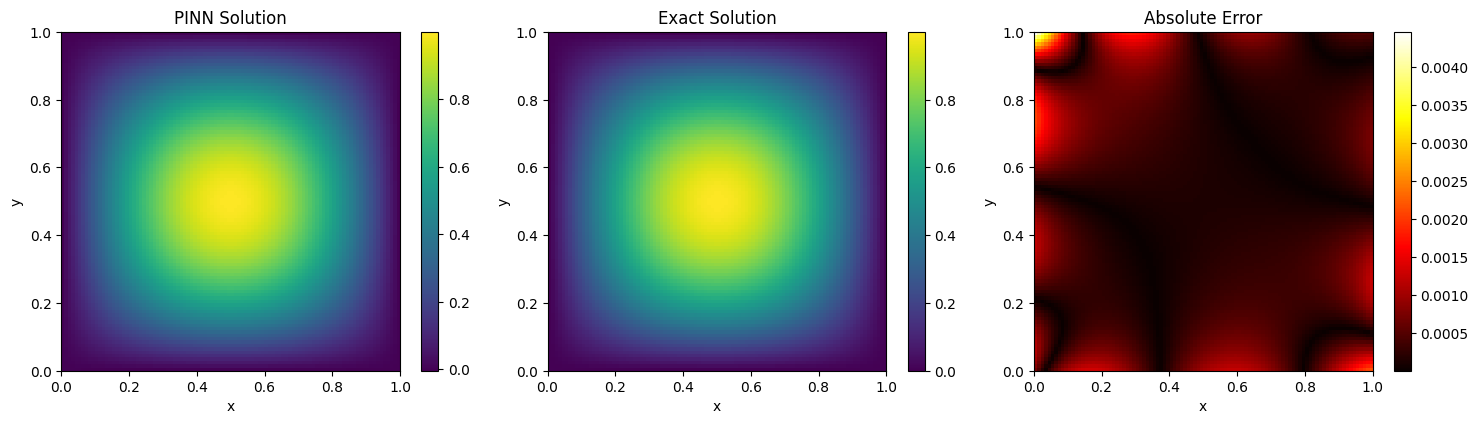

In [13]:
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
model_s.cpu()
u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("PINN Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

Text(0, 0.5, 'loss')

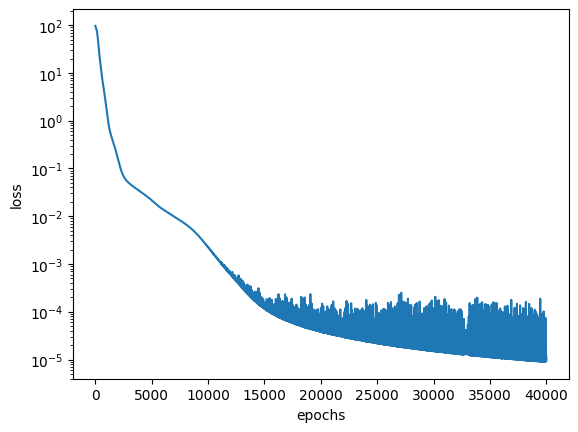

In [14]:

plt.plot(loss_pinn)
plt.yscale("log")
plt.xlabel("epochs")
plt.ylabel("loss")

Postprocessing 

In [9]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [15]:
# Load model trainable parameters
model_s = bsplines(20,3)
loaded_params = torch.load('./results/poisson/model_bsplines.pth')
model_s.coeffs = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_29316\1858842893.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/poisson/model_bspl

In [16]:
loss_bsplines_s = np.load('./results/poisson/bsplines_loss.npy')

In [17]:
layers = [2, 86, 86, 1]
modelp_s = PINN(layers)  # same architecture as used before
modelp_s.load_state_dict(torch.load('./results/poisson/model_pinn.pth'))
modelp_s.eval()  # if you're evaluating


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_29316\2349080427.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  modelp_s.load_state_dict(torch.load('./results/poisson/m

PINN(
  (net): Sequential(
    (layer0): Linear(in_features=2, out_features=86, bias=True)
    (tanh0): Tanh()
    (layer1): Linear(in_features=86, out_features=86, bias=True)
    (tanh1): Tanh()
    (layer2): Linear(in_features=86, out_features=1, bias=True)
  )
)

In [18]:
loss_pinn = np.load('./results/poisson/pinn_loss.npy')

In [61]:
loss_pinn.shape

(40000,)

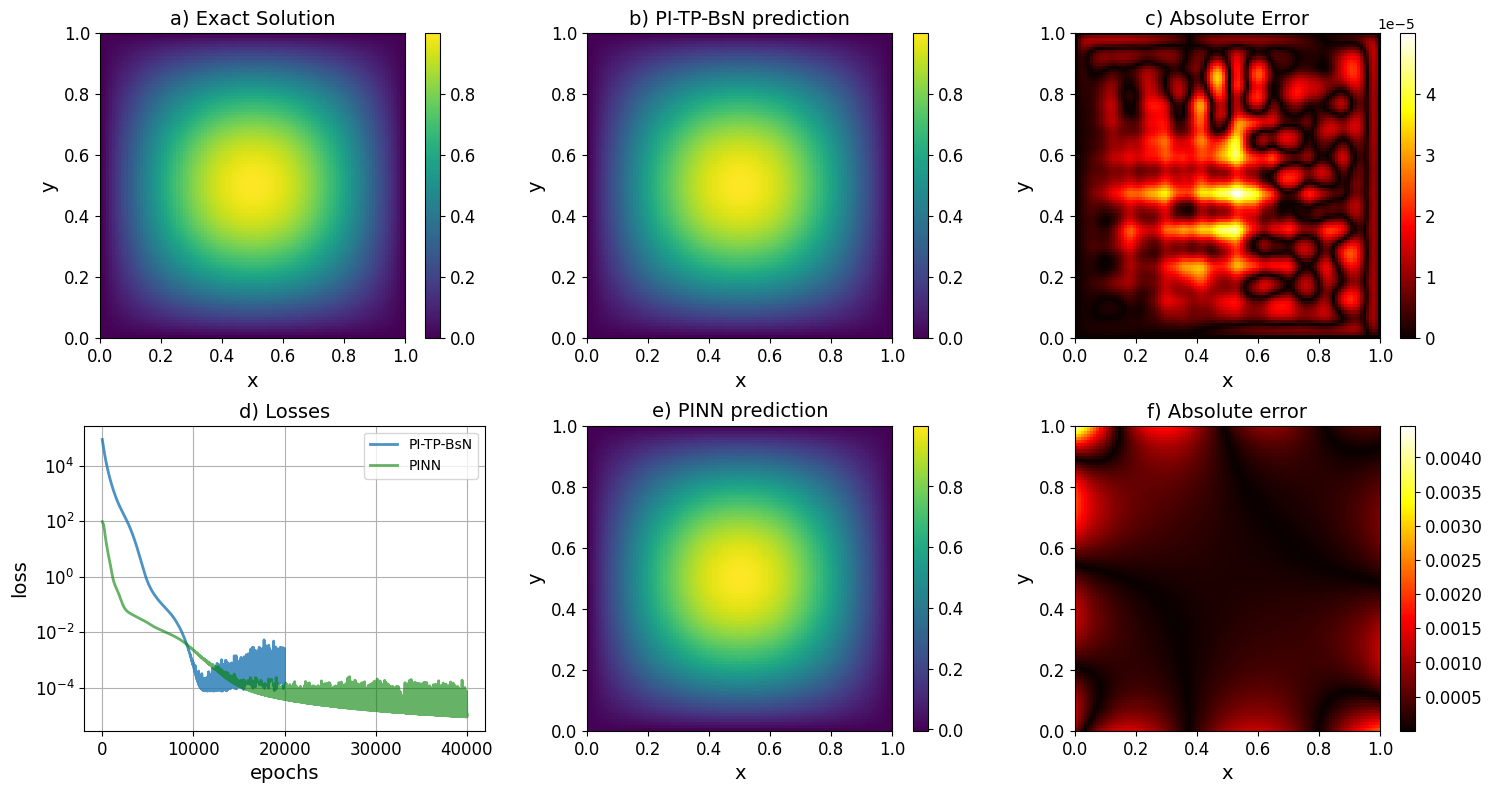

In [19]:
# Figure 5

x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

with torch.no_grad():
    u_predp = modelp_s.forward(XY_torch).numpy().reshape(Xg.shape)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

u_exact = np.sin(np.pi * Xg) * np.sin(np.pi * Yg)

# Exact solution
im0 = axs[0,0].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,0].set_title("a) Exact Solution",fontsize=14)
axs[0,0].set_xlabel("x",fontsize=14)
axs[0,0].set_ylabel("y",fontsize=14)
axs[0,0].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im0, ax=axs[0,0])
cbar.ax.tick_params(labelsize=12) 

# B-splines solution
im1 = axs[0, 1].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,1].set_title("b) PI-TP-BsN prediction",fontsize=14)
axs[0,1].set_xlabel("x",fontsize=14)
axs[0,1].set_ylabel("y",fontsize=14)
axs[0,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im1, ax=axs[0, 1])
cbar.ax.tick_params(labelsize=12) 

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[0, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[0,2].set_title("c) Absolute Error",fontsize=14)
axs[0,2].set_xlabel("x",fontsize=14)
axs[0,2].set_ylabel("y",fontsize=14)
axs[0,2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im2, ax=axs[0, 2])
cbar.ax.tick_params(labelsize=12) 

# Losses
x_a = np.arange(len(loss_bsplines_s))
x_b = np.arange(len(loss_pinn))
axs[1, 0].plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
axs[1, 0].plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
axs[1, 0].legend()
axs[1, 0].set_yscale('log')
axs[1,0].set_title("d) Losses",fontsize=14)
axs[1,0].set_xlabel("epochs",fontsize=14)
axs[1,0].set_ylabel("loss",fontsize=14)
axs[1,0].tick_params(axis='both', labelsize=12)
axs[1,0].grid(True)

# cbar = fig.colorbar(im3, ax=axs[1, 0])
# cbar.ax.tick_params(labelsize=12) 

# Absolute error
im4 = axs[1, 1].imshow(u_predp, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1,1].set_title("e) PINN prediction",fontsize=14)
axs[1,1].set_xlabel("x",fontsize=14)
axs[1,1].set_ylabel("y",fontsize=14)
axs[1,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im4, ax=axs[1, 1])
cbar.ax.tick_params(labelsize=12) 

# Exact solution
error = np.abs(u_predp - u_exact)
im5 = axs[1, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[1, 2].set_title("f) Absolute error",fontsize=14)
axs[1, 2].set_xlabel("x",fontsize=14)
axs[1, 2].set_ylabel("y",fontsize=14)
axs[1, 2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im5, ax=axs[1, 2])
cbar.ax.tick_params(labelsize=12) 


# for ax in axs:
#     ax.set_xlabel("x",fontsize=14)
#     ax.set_ylabel("y",fontsize=14)
#     ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
# fig.savefig("poisson1.pdf", dpi=300)
plt.show()

In [18]:
loss_bsplines_s[-1]

0.0005466245347633958

In [19]:
loss_pinn[-1]

9.571022019372322e-06

In [20]:
re = np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re

2.5082318421850016e-05

In [21]:
re_p = np.sqrt(np.sum((u_predp - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re_p

0.0010297603706538464

In [17]:
(re_p-re)/re_p

0.9756425677889276

In [9]:
error = np.abs(u_pred - u_exact)
error.max()


4.990332949683651e-05

In [10]:
errorp = np.abs(u_predp - u_exact)
errorp.max()


0.004464972764253616

In [12]:
errorp.max()/error.max()

89.47244220521722

In [20]:
import math

a = 0.01
b = 0.003
delta_order = abs(math.log10(loss_pinn[-1]) - math.log10(loss_bsplines_s[-1]))
print(f"Difference in orders of magnitude: {delta_order}")


Difference in orders of magnitude: 1.7567308053401738
